In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from matplotlib.patches import Rectangle

import os
import random


DATASET_ROOT = Path("metal_nut")
OUTPUT_ROOT = Path("outputs/task1_labels")
CATEGORIES = ["bent", "color", "flip", "scratch"]

CLASS_NAMES = {0: "defect"}
NUM_CLASSES = len(CLASS_NAMES)
CLASS_ID = 0

LABEL_ROOT = OUTPUT_ROOT / "labels"
LABEL_ROOT.mkdir(parents=True, exist_ok=True)


In [2]:
def load_image(image_path):
    image = np.array(Image.open(image_path).convert("RGB"))
    return image

def load_mask(mask_path):
    mask = np.array(Image.open(mask_path))
    # Convert multichannel masks to binary if necessary.
    if mask.ndim == 3:
        binary_mask = np.any(mask > 0, axis=2)
    else:
        binary_mask = mask > 0
    return mask, binary_mask.astype(np.uint8)

In [3]:
def extract_connected_components(binary_mask):
    num_labels, labels, stats, centroids = (cv2.connectedComponentsWithStats(binary_mask, connectivity=8))
    components = []

    for component_id in range(1, num_labels):
        x, y, w, h, area = stats[component_id]
        component = {"x": int(x), "y": int(y), "width": int(w), "height": int(h), "area": int(area)}
        components.append(component)

    # Consistent ordering of bounding boxes.
    components.sort(key=lambda item: (item["y"], item["x"]))
    return components

In [4]:
def extract_whole_mask_bbox(binary_mask):

    ys, xs = np.where(binary_mask > 0)
    if len(xs) == 0:
        return []

    x_min = int(xs.min())
    x_max = int(xs.max()) + 1

    y_min = int(ys.min())
    y_max = int(ys.max()) + 1

    bbox = {"x": x_min, "y": y_min, "width": x_max - x_min, "height": y_max - y_min, "area": int(binary_mask.sum())}

    return [bbox]

In [5]:
def generate_bounding_boxes(binary_mask, category):
    if category == "flip":
        boxes = extract_whole_mask_bbox(binary_mask)
    else:
        boxes = extract_connected_components(binary_mask)
    return boxes

In [6]:
def convert_to_yolo(bbox, image_width, image_height):
    x = bbox["x"]
    y = bbox["y"]
    w = bbox["width"]
    h = bbox["height"]

    x_center = (x + w / 2) / image_width
    y_center = (y + h / 2) / image_height
    normalized_width = w / image_width
    normalized_height = h / image_height

    return [CLASS_ID, x_center,y_center, normalized_width, normalized_height]

In [7]:
bbox_records = []
image_records = []

for category in CATEGORIES:

    print(f"Category: {category.upper()}")

    image_dir = DATASET_ROOT / "test" / category
    mask_dir = DATASET_ROOT / "ground_truth" / category
    output_dir = LABEL_ROOT / category

    image_paths = sorted(image_dir.glob("*.png"))

    for image_path in image_paths:
        # Corresponding ground-truth mask.
        mask_path = (mask_dir / f"{image_path.stem}_mask.png")

        if not mask_path.exists():
            raise FileNotFoundError(f"Mask missing for {image_path.name}")
        # Load image and mask.
        image = load_image(image_path)
        original_mask, binary_mask = load_mask(mask_path)

        image_height, image_width = image.shape[:2]
        mask_height, mask_width = binary_mask.shape

        # Ensure image and mask alignment.
        assert (image_width == mask_width and image_height == mask_height), f"Dimension mismatch: {image_path.name}"

        # Ensure the mask contains a foreground region.
        if binary_mask.sum() == 0:
            raise ValueError(f"Empty defect mask: {mask_path}")

        # Generate bounding boxes.
        boxes = generate_bounding_boxes(binary_mask, category)

        if len(boxes) == 0:
            raise ValueError(f"No bounding boxes generated: {image_path.name}")

        yolo_annotations = []

        # Convert each bounding box.
        for bbox_id, bbox in enumerate(boxes):
            yolo_bbox = convert_to_yolo(bbox, image_width, image_height)

            # Validate normalized coordinates.
            assert all(0 <= value <= 1 for value in yolo_bbox[1:])

            assert yolo_bbox[3] > 0
            assert yolo_bbox[4] > 0

            yolo_annotations.append(yolo_bbox)

            # Store detailed annotation metadata.
            bbox_records.append({
                "category": category,
                "image": image_path.name,
                "bbox_id": bbox_id,

                "x": bbox["x"],
                "y": bbox["y"],

                "width": bbox["width"],
                "height": bbox["height"],

                "area_px": bbox["area"],

                "class_id": CLASS_ID,

                "x_center": yolo_bbox[1],
                "y_center": yolo_bbox[2],

                "normalized_width": yolo_bbox[3],
                "normalized_height": yolo_bbox[4]

            })

        # Save YOLO TXT file.
        label_path = (output_dir / f"{image_path.stem}.txt")

        # Ensure the output directory exists.
        label_path.parent.mkdir(parents=True, exist_ok=True)

        with open(label_path, "w") as file:
            for annotation in yolo_annotations:
                line = (f"{annotation[0]} {annotation[1]:.6f} {annotation[2]:.6f} {annotation[3]:.6f} {annotation[4]:.6f}\n")
                file.write(line)

        # Image-level metadata.
        image_records.append({

            "category": category,
            "image": image_path.name,

            "mask": mask_path.name,

            "image_width": image_width,
            "image_height": image_height,

            "defect_coverage_pct": (binary_mask.mean() * 100),

            "bbox_count": len(boxes),

            "label_path": str(label_path)
        })

    print(f"Images processed: {len(image_paths)}")


bbox_df = pd.DataFrame(bbox_records)
image_df = pd.DataFrame(image_records)

print("\n" + "=" * 55)
print("ANNOTATION GENERATION COMPLETED")
print("=" * 55)

print("Images annotated:", len(image_df))
print("Total bounding boxes:", len(bbox_df))

Category: BENT
Images processed: 25
Category: COLOR
Images processed: 22
Category: FLIP
Images processed: 23
Category: SCRATCH
Images processed: 23

ANNOTATION GENERATION COMPLETED
Images annotated: 93
Total bounding boxes: 132


---
#### **TASK 2 - Training**

In [8]:
import shutil
import json
import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.model_selection import train_test_split

SEED = 42

DATASET_ROOT = Path("metal_nut")
TASK1_LABEL_ROOT = Path("outputs/task1_labels/labels")
DETECTION_ROOT = Path("outputs/task2_dataset")

CATEGORIES = ["bent", "color", "flip", "scratch"]
SPLITS = ["train", "val", "test"]
CLASS_NAMES = {0: "defect"}


print("Configuration ready.")

Configuration ready.


In [9]:
positive_records = []

for category in CATEGORIES:

    image_dir = DATASET_ROOT / "test" / category
    label_dir = TASK1_LABEL_ROOT / category

    for image_path in sorted(image_dir.glob("*.png")):
        label_path = label_dir / f"{image_path.stem}.txt"

        positive_records.append({"category": category, "image_path": image_path, "label_path": label_path})


positive_df = pd.DataFrame(positive_records)
assert len(positive_df) == 93

print("Total defective images:", len(positive_df))

display(positive_df.groupby("category").size())

Total defective images: 93


category
bent       25
color      22
flip       23
scratch    23
dtype: int64

In [ ]:
# Stage 1: 70% training, 30% temporary holdout

positive_train_df, positive_holdout_df = train_test_split(positive_df, test_size=0.30, stratify=positive_df["category"])

# Stage 2: Divide holdout equally into validation and test
positive_val_df, positive_test_df = train_test_split(positive_holdout_df, test_size=0.50, stratify=positive_holdout_df["category"])
positive_splits = {"train": positive_train_df, "val": positive_val_df, "test": positive_test_df}

print("Defective image distribution:")

for split, df in positive_splits.items():
    print(f"\n{split.upper()}: {len(df)} images")
    print(df["category"].value_counts().sort_index())


assert set(positive_train_df["image_path"]).isdisjoint(set(positive_val_df["image_path"]))
assert set(positive_train_df["image_path"]).isdisjoint(set(positive_test_df["image_path"]))
assert set(positive_val_df["image_path"]).isdisjoint(set(positive_test_df["image_path"]))

Defective image distribution:

TRAIN: 65 images
category
bent       18
color      15
flip       16
scratch    16
Name: count, dtype: int64

VAL: 14 images
category
bent       4
color      3
flip       4
scratch    3
Name: count, dtype: int64

TEST: 14 images
category
bent       3
color      4
flip       3
scratch    4
Name: count, dtype: int64


In [11]:
normal_train_paths = sorted((DATASET_ROOT / "train" / "good").glob("*.png"))
normal_test_paths = sorted((DATASET_ROOT / "test" / "good").glob("*.png"))

normal_train, normal_val = train_test_split(normal_train_paths, test_size=0.20)
normal_splits = {"train": normal_train, "val": normal_val, "test": normal_test_paths}

print("Normal image distribution:")
for split, paths in normal_splits.items():
    print(f"{split.upper()}: {len(paths)} images")


Normal image distribution:
TRAIN: 176 images
VAL: 44 images
TEST: 22 images


In [12]:
dataset_records = []

# Defective images

for split, df in positive_splits.items():
    for row in df.itertuples(index=False):

        image_path = row.image_path
        label_path = row.label_path
        category = row.category

        destination_name = (f"{category}_{image_path.stem}.png")
        dataset_records.append({
            "split": split,
            "category": category,
            "is_defective": True,
            "source_image": image_path,
            "source_label": label_path,
            "destination_name": destination_name
        })

# Normal images

for split, paths in normal_splits.items():
    for image_path in paths:
        destination_name = (f"good_{split}_{image_path.stem}.png")

        dataset_records.append({
            "split": split,
            "category": "good",
            "is_defective": False,
            "source_image": image_path,
            "source_label": None,
            "destination_name": destination_name

        })


split_df = pd.DataFrame(dataset_records)

print("Total dataset records:", len(split_df))
display(split_df.head())

Total dataset records: 335


,split,category,is_defective,source_image,source_label,destination_name
0,train,bent,True,metal_nut/test/bent/007.png,outputs/task1_labels/labels/bent/007.txt,bent_007.png
1,train,flip,True,metal_nut/test/flip/007.png,outputs/task1_labels/labels/flip/007.txt,flip_007.png
2,train,flip,True,metal_nut/test/flip/018.png,outputs/task1_labels/labels/flip/018.txt,flip_018.png
3,train,color,True,metal_nut/test/color/009.png,outputs/task1_labels/labels/color/009.txt,color_009.png
4,train,scratch,True,metal_nut/test/scratch/001.png,outputs/task1_labels/labels/scratch/001.txt,scratch_001.png


In [13]:


# Create directory structure.
for split in SPLITS:
    (DETECTION_ROOT / "images" / split).mkdir(parents=True, exist_ok=True)
    (DETECTION_ROOT / "labels" / split).mkdir(parents=True, exist_ok=True)

# Copy images and labels.

for row in split_df.itertuples(index=False):
    split = row.split
    image_source = Path(row.source_image)
    image_destination = (DETECTION_ROOT / "images" / split / row.destination_name)
    label_destination = (DETECTION_ROOT / "labels" / split / f"{Path(row.destination_name).stem}.txt")

    # Copy original image.
    shutil.copy2(image_source, image_destination)

    # Copy defect annotations or create an empty label.
    if row.is_defective:
        shutil.copy2(Path(row.source_label), label_destination)

    else:
        label_destination.write_text("")


print("YOLO dataset created successfully.")
print("Location:", DETECTION_ROOT.resolve())

YOLO dataset created successfully.
Location: /run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/All Projects/All Projects/mvtec/outputs/task2_dataset


In [14]:
### ultralytics uses .yaml file to understand classes, files names, etc. This is a required file for training and validation.

DATA_YAML = DETECTION_ROOT / "data.yaml"

yaml_content = f"""
path: {json.dumps(str(DETECTION_ROOT.resolve()))}

train: images/train
val: images/val
test: images/test

names:
  0: defect
"""

DATA_YAML.write_text(yaml_content.strip() + "\n", encoding="utf-8")
print(DATA_YAML.read_text())

path: "/run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/All Projects/All Projects/mvtec/outputs/task2_dataset"

train: images/train
val: images/val
test: images/test

names:
  0: defect



In [ ]:
### training

from ultralytics import YOLO

model = YOLO("yolo26n.pt")

results = model.train(data=str(DATA_YAML), epochs=100, imgsz=700, batch=32, device=0, patience=20, seed=42, project="outputs/task2_training", name="yolo26n_baseline", plots=True)

New https://pypi.org/project/ultralytics/8.4.203 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.178 🚀 Python-3.10.21 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 5806MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=outputs/task2_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=700, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=trai

#### Evaluation

In [17]:
from ultralytics import YOLO
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

model = YOLO("/run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/All Projects/All Projects/mvtec/runs/detect/outputs/task2_training/yolo26n_baseline-2/weights/best.pt")
DATA_YAML = "outputs/task2_dataset/data.yaml"

# Evaluate on held-out test set
metrics = model.val(data=DATA_YAML, split="test", imgsz=700, batch=32, conf=0.001, plots=True)

# Extract metrics
precision = metrics.box.mp
recall = metrics.box.mr
map50 = metrics.box.map50

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"mAP@0.5:   {map50:.4f}")

WARNING ⚠️ imgsz=[700] must be multiple of max stride 32, updating to [704]
Ultralytics 8.4.178 🚀 Python-3.10.21 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 5806MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4955.8±2707.4 MB/s, size: 475.9 KB)
val: Scanning /run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/All Projects/All Projects/mvtec/outputs/task2_dataset/labels/test... 47 images, 22 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 47/47 998.3it/s 0.0s
val: New cache created: /run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/All Projects/All Projects/mvtec/outputs/task2_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.0it/s 1.0s2.7s
                   all         47         38      0.963      0.816      0.897      0.762
Speed: 2.4

In [ ]:
TEST_DIR = Path("outputs/task2_dataset/images/test")
LABEL_DIR = Path("outputs/task2_dataset/labels/test")

iou_thres = 0.5


def calculate_iou(a, b):

    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area_a = (a[2]-a[0]) * (a[3]-a[1])
    area_b = (b[2]-b[0]) * (b[3]-b[1])

    union = area_a + area_b - intersection

    return intersection / union


# Run predictions on test images
results = model.predict(source=str(TEST_DIR), imgsz=700, conf=0.25, save=False, verbose=False)

failure_cases = []
for result in results:

    image_name = Path(result.path).name
    h, w = result.orig_shape

    label_path = LABEL_DIR / f"{Path(image_name).stem}.txt"

    # Load ground-truth boxes
    gt_boxes = []

    for line in label_path.read_text().splitlines():
        if not line.strip():
            continue

        _, xc, yc, bw, bh = map(float, line.split())
        gt_boxes.append([(xc-bw/2)*w, (yc-bh/2)*h, (xc+bw/2)*w, (yc+bh/2)*h])

    gt_boxes = np.array(gt_boxes).reshape(-1, 4)

    # Predicted boxes
    pred_boxes = (result.boxes.xyxy.cpu().numpy() if result.boxes is not None else np.empty((0, 4)))
    scores = (result.boxes.conf.cpu().numpy() if result.boxes is not None else np.empty(0))

    matched_gt = set()
    false_positives = []

    # Match predictions with ground truth
    for idx in np.argsort(-scores):
        ious = [calculate_iou(pred_boxes[idx], gt) if j not in matched_gt else 0 for j, gt in enumerate(gt_boxes)]

        if len(ious) and max(ious) >= iou_thres:
            matched_gt.add(int(np.argmax(ious)))

        else:
            false_positives.append(int(idx))

    false_negatives = [i for i in range(len(gt_boxes)) if i not in matched_gt]

    if false_positives or false_negatives:

        failure_cases.append({
            "image": image_name,
            "gt": gt_boxes,
            "pred": pred_boxes,
            "fp": false_positives,
            "fn": false_negatives,
            "matched": matched_gt,
            "scores": scores
        })


print("Total images:", len(results))
print("Images containing failures:", len(failure_cases))
print("Total FP:", sum(len(x["fp"]) for x in failure_cases))
print("Total FN:", sum(len(x["fn"]) for x in failure_cases))

WARNING ⚠️ imgsz=[700] must be multiple of max stride 32, updating to [704]
Total images: 47
Images containing failures: 2
Total FP: 4
Total FN: 5


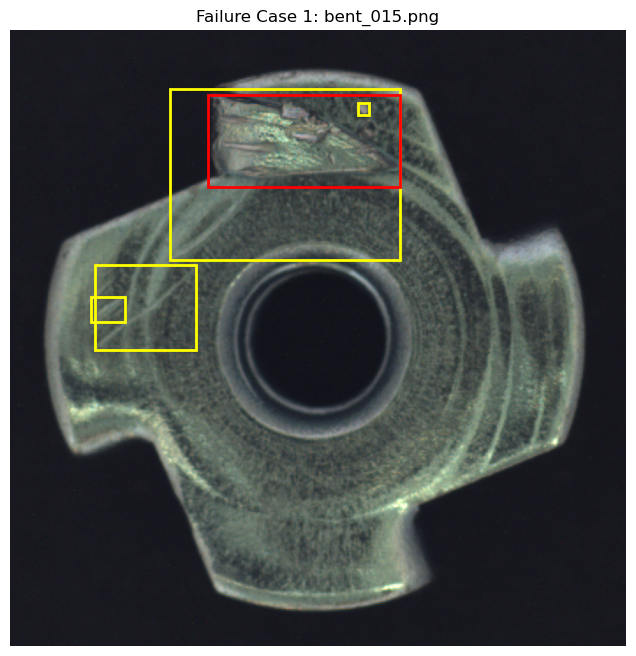

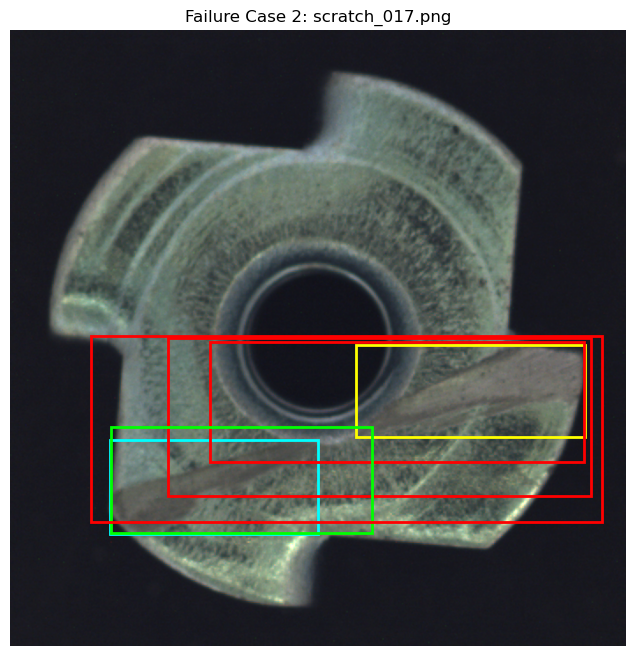

In [ ]:
failure_cases.sort(key=lambda x: len(x["fp"]) + len(x["fn"]), reverse=True)

for i, case in enumerate(failure_cases[:5], 1):
    image = cv2.imread(str(TEST_DIR / case["image"]))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(image)

    # Ground-truth boxes
    for j, box in enumerate(case["gt"]):
        color = "yellow" if j in case["fn"] else "cyan"

        x1, y1, x2, y2 = box
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, linewidth=2, edgecolor=color, facecolor="none"))

    # Predicted boxes
    for j, box in enumerate(case["pred"]):
        color = "red" if j in case["fp"] else "lime"

        x1, y1, x2, y2 = box
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, linewidth=2, edgecolor=color, facecolor="none"))

    ax.set_title(f"Failure Case {i}: {case['image']}")
    ax.axis("off")

    plt.show()

In [ ]:
metrics = model.val(data=str(DATA_YAML), split="test", imgsz=700, batch=32, conf=0.001, plots=True, project="outputs/task3_evaluation", name="corrected_test")

precision = metrics.box.mp
recall = metrics.box.mr
map50 = metrics.box.map50
map50_95 = metrics.box.map

print("=" * 45)
print("TASK 3 — FINAL TEST RESULTS")
print("=" * 45)

print(f"Test images: {metrics.box.image_count if hasattr(metrics.box, 'image_count') else 36}")
print(f"Precision:   {precision:.4f}")
print(f"Recall:      {recall:.4f}")
print(f"mAP@0.5:     {map50:.4f}")
print(f"mAP@0.5:0.95: {map50_95:.4f}")

Ultralytics 8.4.178 🚀 Python-3.10.21 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 5806MiB)


YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6833.5±1123.8 MB/s, size: 484.3 KB)
val: Scanning /run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/All Projects/All Projects/mvtec/outputs/task2_dataset/labels/test... 36 images, 22 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 36/36 1.0Kit/s 0.0s
val: New cache created: /run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/All Projects/All Projects/mvtec/outputs/task2_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.0it/s 1.0s2.8s
                   all         36         22      0.991      0.727      0.819      0.683
Speed: 3.0ms preprocess, 4.3ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to /run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/All Projects/All

In [ ]:
results = model.predict(source=str(TEST_DIR), imgsz=704, conf=0.25, iou=0.70, save=False, verbose=False
)

failure_cases = []

for result in results:

    image_name = Path(result.path).name
    h, w = result.orig_shape

    label_path = LABEL_DIR / f"{Path(image_name).stem}.txt"

    gt_boxes = []

    for line in label_path.read_text().splitlines():

        if not line.strip():
            continue

        _, xc, yc, bw, bh = map(float, line.split())

        gt_boxes.append([ (xc-bw/2)*w, (yc-bh/2)*h, (xc+bw/2)*w, (yc+bh/2)*h ])

    gt_boxes = np.array(gt_boxes).reshape(-1, 4)

    pred_boxes = (result.boxes.xyxy.cpu().numpy() if result.boxes is not None else np.empty((0, 4)))
    scores = (result.boxes.conf.cpu().numpy() if result.boxes is not None else np.empty(0))
    

    matched_gt = set()
    fp = []

    for idx in np.argsort(-scores):

        ious = [calculate_iou(pred_boxes[idx], gt) if j not in matched_gt else 0 for j, gt in enumerate(gt_boxes)]

        if len(ious) and max(ious) >= 0.5:
            matched_gt.add(int(np.argmax(ious)))
        else:
            fp.append(int(idx))

    fn = [j for j in range(len(gt_boxes)) if j not in matched_gt]

    if fp or fn:
        failure_cases.append({
            "image": image_name,
            "gt": gt_boxes,
            "pred": pred_boxes,
            "fp": fp,
            "fn": fn,
            "scores": scores
        })


print("Test images:", len(results))
print("Images with failures:", len(failure_cases))
print("False positives:", sum(len(x["fp"]) for x in failure_cases))
print("False negatives:", sum(len(x["fn"]) for x in failure_cases))

Test images: 36
Images with failures: 2
False positives: 4
False negatives: 5


Total failure events: 9


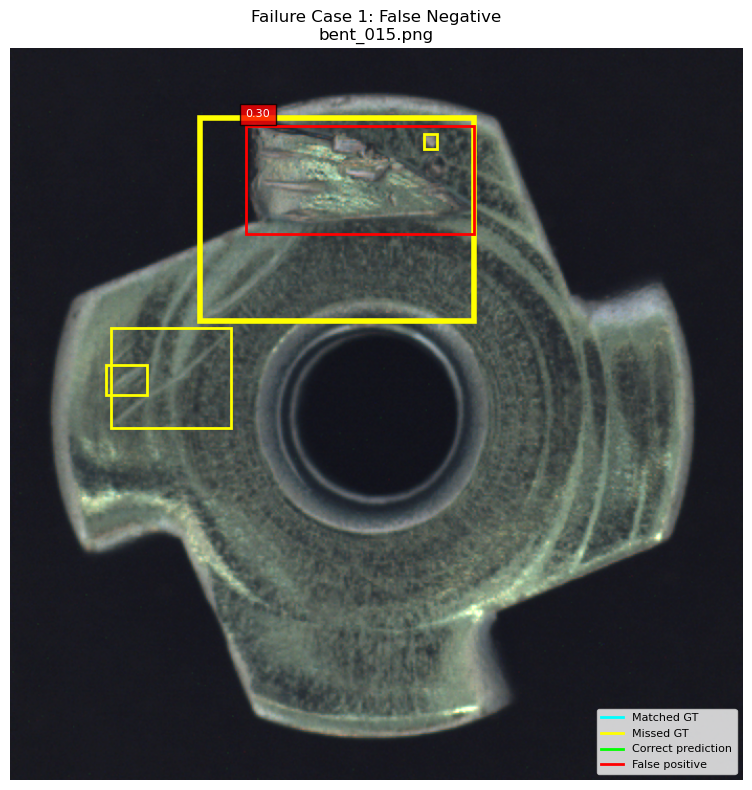

Saved: outputs/task3_evaluation/failure_cases/failure_case_1.png


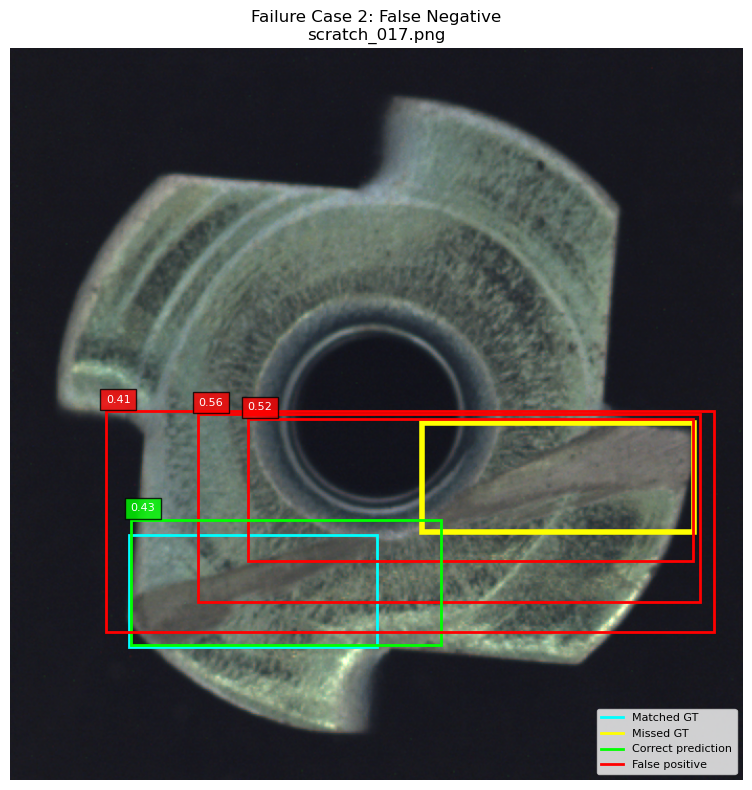

Saved: outputs/task3_evaluation/failure_cases/failure_case_2.png


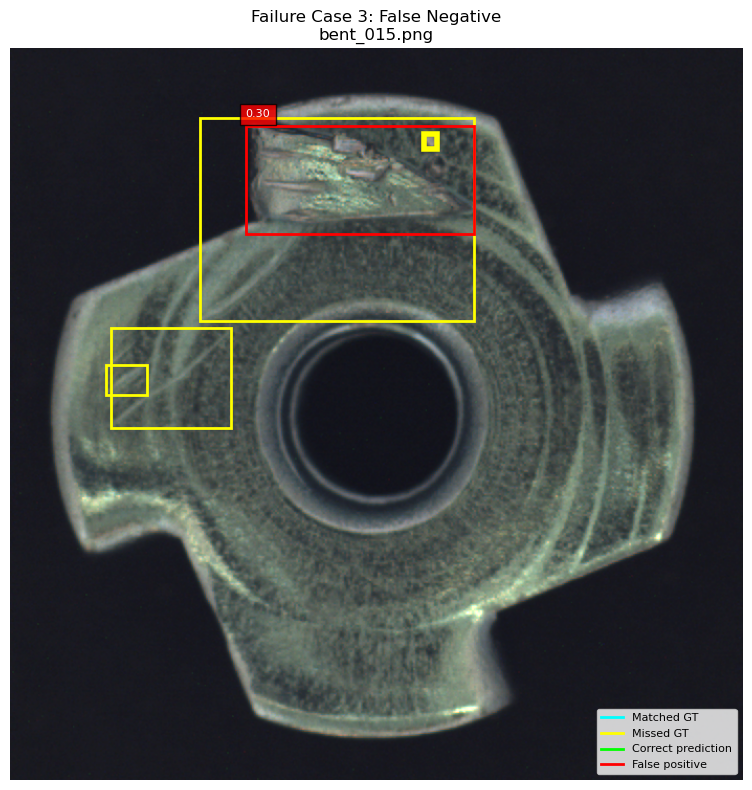

Saved: outputs/task3_evaluation/failure_cases/failure_case_3.png


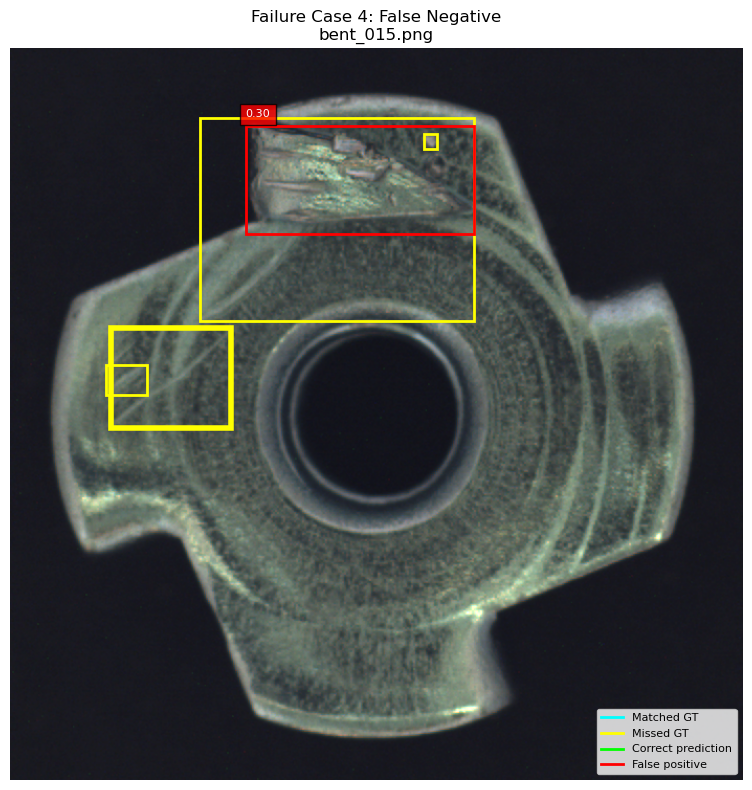

Saved: outputs/task3_evaluation/failure_cases/failure_case_4.png


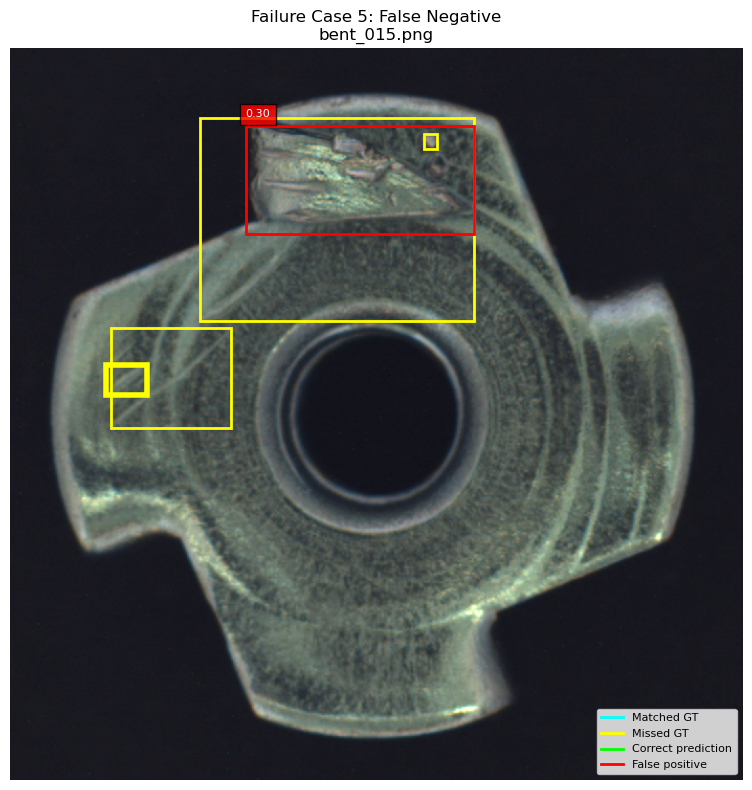

Saved: outputs/task3_evaluation/failure_cases/failure_case_5.png

Visualized 5 failure events from 2 unique images.


In [30]:
from pathlib import Path
from matplotlib.lines import Line2D

FAILURE_DIR = Path("outputs/task3_evaluation/failure_cases")
FAILURE_DIR.mkdir(parents=True, exist_ok=True)

# Collect individual failure events
failure_events = []

for case in failure_cases:

    for idx in case["fn"]:
        failure_events.append({
            "case": case,
            "type": "False Negative",
            "index": idx
        })

    for idx in case["fp"]:
        failure_events.append({
            "case": case,
            "type": "False Positive",
            "index": idx
        })


print("Total failure events:", len(failure_events))

if not failure_events:

    print("No failure cases found at the selected confidence threshold.")

else:

    # -----------------------------------------
    # Select diverse failure events
    # -----------------------------------------

    selected_events = []
    selected_event_ids = set()
    seen_images = set()

    # First priority: one failure per unique image.
    for event in failure_events:

        image_name = event["case"]["image"]

        if image_name not in seen_images:

            selected_events.append(event)
            seen_images.add(image_name)
            selected_event_ids.add(id(event))

        if len(selected_events) == 5:
            break

    # Fill remaining slots if fewer than 5 unique
    # images contain failures.
    for event in failure_events:

        if id(event) not in selected_event_ids:

            selected_events.append(event)
            selected_event_ids.add(id(event))

        if len(selected_events) == 5:
            break


    # -----------------------------------------
    # Visualize selected failure events
    # -----------------------------------------

    for i, event in enumerate(selected_events, 1):

        case = event["case"]
        event_type = event["type"]
        event_idx = event["index"]
        image_name = case["image"]

        image_path = TEST_DIR / image_name

        image = cv2.imread(str(image_path))

        if image is None:
            raise FileNotFoundError(image_path)

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        fig, ax = plt.subplots(figsize=(8, 8))
        ax.imshow(image)

        # Ground-truth boxes
        for j, box in enumerate(case["gt"]):

            x1, y1, x2, y2 = box

            missed = j in case["fn"]

            highlight = (
                event_type == "False Negative"
                and event_idx == j
            )

            color = "yellow" if missed else "cyan"

            ax.add_patch(Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=4 if highlight else 2,
                edgecolor=color,
                facecolor="none"
            ))

        # Predicted boxes
        for j, box in enumerate(case["pred"]):

            x1, y1, x2, y2 = box

            false_positive = j in case["fp"]

            highlight = (
                event_type == "False Positive"
                and event_idx == j
            )

            color = "red" if false_positive else "lime"

            ax.add_patch(Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=4 if highlight else 2,
                edgecolor=color,
                facecolor="none"
            ))

            ax.text(
                x1,
                max(0, y1 - 8),
                f"{case['scores'][j]:.2f}",
                color="white",
                fontsize=8,
                bbox=dict(
                    facecolor=color,
                    alpha=0.8
                )
            )

        # Legend
        legend = [
            Line2D([0], [0], color="cyan", lw=2, label="Matched GT"),
            Line2D([0], [0], color="yellow", lw=2, label="Missed GT"),
            Line2D([0], [0], color="lime", lw=2, label="Correct prediction"),
            Line2D([0], [0], color="red", lw=2, label="False positive")
        ]

        ax.legend(
            handles=legend,
            loc="lower right",
            fontsize=8
        )

        ax.set_title(
            f"Failure Case {i}: {event_type}\n{image_name}"
        )

        ax.axis("off")
        plt.tight_layout()

        save_path = (
            FAILURE_DIR /
            f"failure_case_{i}.png"
        )

        plt.savefig(
            save_path,
            dpi=150,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

        print("Saved:", save_path)


    print(
        f"\nVisualized {len(selected_events)} failure events "
        f"from {len(set(e['case']['image'] for e in selected_events))} unique images."
    )

---
#### **Task 4 - ONNX Export and CPU benchmarking**

`BEST_PT = Path("/run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/All Projects/All Projects/mvtec/runs/detect/outputs/task2_training/yolo26n_baseline-2/weights/best.pt")`

In [ ]:
from ultralytics import YOLO
from pathlib import Path
import onnx
import onnxruntime as ort
import numpy as np
import pandas as pd
import platform
import time
import shutil

BEST_PT = Path("/run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/All Projects/All Projects/mvtec/runs/detect/outputs/task2_training/yolo26n_baseline-2/weights/best.pt")
TEST_DIR = Path("outputs/task2_dataset/images/test")

OUTPUT_DIR = Path("outputs/task4_onnx")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMGSZ = 256


print("Configuration ready.")

Configuration ready.


In [61]:
# Load trained model
model = YOLO(str(BEST_PT))

# Export FP32 ONNX model
exported_path = Path(model.export(format="onnx", imgsz=IMGSZ, dynamic=False, simplify=True, half=False, device="cpu", nms = False))

# Copy to Task 4 directory
ONNX_PATH = OUTPUT_DIR / "best_fp32.onnx"

shutil.copy2(exported_path, ONNX_PATH)

# Validate ONNX model and CPU execution
onnx.checker.check_model(onnx.load(str(ONNX_PATH)))

session = ort.InferenceSession(str(ONNX_PATH), providers=["CPUExecutionProvider"])

print("ONNX export successful.")
print("Active execution providers:", session.get_providers())
print(f"Model size: {ONNX_PATH.stat().st_size / (1024**2):.2f} MB")

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.178 🚀 Python-3.10.21 torch-2.14.0+cu130 CPU (12th Gen Intel Core i7-12650H)
YOLO26n summary (fused): 122 layers, 2,389,735 parameters, 0 gradients, 0.8 GFLOPs

PyTorch: starting from '/run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/All Projects/All Projects/mvtec/runs/detect/outputs/task2_training/yolo26n_baseline-2/weights/best.pt' with input shape (1, 3, 256, 256) BCHW and output shape(s) (1, 300, 6) (5.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 1.2s, saved as '/run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/All Projects/All Projects/mvtec/runs/detect/outputs/task2_training/yolo26n_baseline-2/weights/best.onnx' (9.3 MB)

Export complete (1.4s)
Results saved to /run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuf

In [62]:
# Load ONNX model
onnx_model = YOLO(str(ONNX_PATH))

test_images = sorted(TEST_DIR.glob("*.png"))

# CPU identification
cpu_name = "i7-12650H"

# Warm-up
for image in test_images[:5]:
    onnx_model.predict(str(image), imgsz=IMGSZ, device="cpu", rect=False, verbose=False)

# Benchmark
inference_times = []
total_times = []

for image in test_images:

    start = time.perf_counter()

    result = onnx_model.predict(str(image), imgsz=IMGSZ, conf=0.25, device="cpu", rect=False, verbose=False)

    total_times.append((time.perf_counter() - start) * 1000)
    inference_times.append(result[0].speed["inference"])

# Calculate statistics
avg_ms = np.mean(inference_times)
median_ms = np.median(inference_times)
p95_ms = np.percentile(inference_times, 95)
avg_total_ms = np.mean(total_times)

print("=" * 45)
print("ONNX CPU BENCHMARK")
print("=" * 45)
print("CPU:", cpu_name)
print("Input resolution:", f"{IMGSZ} x {IMGSZ}")
print("Images:", len(test_images))
print(f"Average inference: {avg_ms:.3f} ms/image")
print(f"Median inference: {median_ms:.3f} ms/image")
print(f"P95 inference: {p95_ms:.3f} ms/image")
print(f"End-to-end latency: {avg_total_ms:.3f} ms/image")
print(f"Inference FPS: {1000 / avg_ms:.2f}")

# Save results
pd.DataFrame({"image": [p.name for p in test_images], "inference_ms": inference_times, "end_to_end_ms": total_times}).to_csv(OUTPUT_DIR / "cpu_benchmark.csv", index=False)

Loading outputs/task4_onnx/best_fp32.onnx for ONNX Runtime inference...


Using ONNX Runtime 1.23.2 with CPUExecutionProvider
ONNX CPU BENCHMARK
CPU: i7-12650H
Input resolution: 256 x 256
Images: 36
Average inference: 10.140 ms/image
Median inference: 8.311 ms/image
P95 inference: 17.101 ms/image
End-to-end latency: 47.418 ms/image
Inference FPS: 98.62


---
#### **Task 5 - Optimization**

In [ ]:
OUTPUT_DIR = Path("outputs/task5_int8")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Static INT8 quantization using training data for calibration
exported_path = model.export(format="onnx", imgsz=256, quantize=8, data=DATA_YAML, fraction=1.0, dynamic=False, device="cpu", nms = False)

# Save INT8 model separately
INT8_PATH = OUTPUT_DIR / "best_int8.onnx"
shutil.copy2(exported_path, INT8_PATH)

# Validate exported model
onnx.checker.check_model(onnx.load(str(INT8_PATH)))

session = ort.InferenceSession(str(INT8_PATH), providers=["CPUExecutionProvider"])

print("INT8 export successful.")
print("Input shape:", session.get_inputs()[0].shape)
print("Execution provider:", session.get_providers())
print(f"Model size: {INT8_PATH.stat().st_size / (1024**2):.2f} MB")

Ultralytics 8.4.178 🚀 Python-3.10.21 torch-2.14.0+cu130 CPU (12th Gen Intel Core i7-12650H)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 0.8 GFLOPs

PyTorch: starting from '/run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/All Projects/All Projects/mvtec/runs/detect/outputs/task2_training/yolo26n_baseline-2/weights/best.pt' with input shape (1, 3, 256, 256) BCHW and output shape(s) (1, 5, 1344) (5.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: collecting INT8 calibration images from 'data=outputs/task2_dataset/data.yaml'
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5873.6±745.9 MB/s, size: 487.0 KB)
val: Scanning /run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/All Projects/All Projects/mvtec/outputs/task2_dataset/labels/val.cache... 103 images, 78 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 103/103 24.0Mit/s 0.0s
WARNING ⚠️ ONNX: >300 ima

ONNX: export success ✅ 6.0s, saved as '/run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/All Projects/All Projects/mvtec/runs/detect/outputs/task2_training/yolo26n_baseline-2/weights/best_int8.onnx' (2.7 MB)

Export complete (6.4s)
Results saved to /run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/All Projects/All Projects/mvtec/runs/detect/outputs/task2_training/yolo26n_baseline-2/weights/best_int8.onnx
Predict:         yolo predict task=detect model=/run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/All Projects/All Projects/mvtec/runs/detect/outputs/task2_training/yolo26n_baseline-2/weights/best_int8.onnx imgsz=256 
Validate:        yolo val task=detect model=/run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/All Projects/All Projects/mvtec/runs/detect/outputs/task2_training/yolo26n_baseline-2/weights/best_int8.onnx imgsz=256 data=outputs/task2_dataset/data.yaml 

In [64]:
FP32_PATH = Path("outputs/task4_onnx/best_fp32.onnx")

models = {"FP32": YOLO(str(FP32_PATH)), "INT8": YOLO(str(INT8_PATH))}

accuracy_results = {}

for name, detector in models.items():
    metrics = detector.val(data=DATA_YAML, split="test", imgsz=416, batch=1, conf=0.001, device="cpu", plots=True, project=str(OUTPUT_DIR), name=f"{name.lower()}_evaluation")

    accuracy_results[name] = {"Precision": metrics.box.mp, "Recall": metrics.box.mr, "mAP50": metrics.box.map50, "mAP50-95": metrics.box.map}

accuracy_df = pd.DataFrame(accuracy_results).T

display(accuracy_df.round(4))

Ultralytics 8.4.178 🚀 Python-3.10.21 torch-2.14.0+cu130 CPU (12th Gen Intel Core i7-12650H)
Loading outputs/task4_onnx/best_fp32.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.23.2 with CPUExecutionProvider
Setting batch=1 input of shape (1, 3, 256, 256)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6884.3±608.1 MB/s, size: 484.6 KB)
val: Scanning /run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/All Projects/All Projects/mvtec/outputs/task2_dataset/labels/test.cache... 36 images, 22 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 36/36 11.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 21.6it/s 1.7s0.1s
                   all         36         22      0.835      0.773      0.756      0.619
Speed: 12.8ms preprocess, 12.3ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to /run/media/sparsh/CaptainSlow/Programming Stuff/Programming Stuff/Code _n_ Stuff/A

,Precision,Recall,mAP50,mAP50-95
FP32,0.8353,0.7727,0.7556,0.6185
INT8,0.8835,0.7273,0.7820,0.5646


In [65]:
TEST_DIR = Path("outputs/task2_dataset/images/test")
test_images = sorted(TEST_DIR.glob("*.png"))

benchmark_results = {}

for name, detector in models.items():

    # Warm-up
    for image in test_images[:5]:
        detector.predict(str(image), imgsz=256, device="cpu", rect=False, verbose=False)

    inference_times = []
    total_times = []

    # Benchmark
    for image in test_images:

        start = time.perf_counter()

        result = detector.predict( str(image),imgsz=256, conf=0.25, device="cpu", rect=False, verbose=False)

        total_times.append((time.perf_counter() - start) * 1000)

        inference_times.append(result[0].speed["inference"])

    benchmark_results[name] = {
        "Model Size (MB)": (FP32_PATH.stat().st_size if name == "FP32" else INT8_PATH.stat().st_size) / (1024**2),
        "Average Inference (ms)": np.mean(inference_times),
        "Median Inference (ms)": np.median(inference_times),
        "P95 Inference (ms)": np.percentile(inference_times, 95),
        "End-to-End (ms)": np.mean(total_times),
        "Inference FPS": 1000 / np.mean(inference_times)
    }

benchmark_df = pd.DataFrame(benchmark_results).T

display(benchmark_df.round(3))

benchmark_df.to_csv(OUTPUT_DIR / "fp32_vs_int8_benchmark.csv")
accuracy_df.to_csv(OUTPUT_DIR / "fp32_vs_int8_accuracy.csv")

Loading outputs/task4_onnx/best_fp32.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.23.2 with CPUExecutionProvider
Loading outputs/task5_int8/best_int8.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.23.2 with CPUExecutionProvider


,Model Size (MB),Average Inference (ms),Median Inference (ms),P95 Inference (ms),End-to-End (ms),Inference FPS
FP32,9.272,11.929,13.475,17.300,47.050,83.831
INT8,2.658,13.247,13.398,18.135,47.884,75.492


In [68]:
import cv2
import onnxruntime as ort
import numpy as np
import time
from pathlib import Path

ONNX_PATH = INT8_PATH
TEST_DIR = Path("outputs/task2_dataset/images/test")

session = ort.InferenceSession(
    ONNX_PATH,
    providers=["CPUExecutionProvider"]
)

input_name = session.get_inputs()[0].name

test_images = sorted(TEST_DIR.glob("*.png"))

preprocess_times = []
inference_times = []
total_times = []
load_times = []
postprocess_times = []

# Warm-up
for path in test_images[:5]:

    image = cv2.imread(str(path))

    blob = cv2.dnn.blobFromImage(
        image,
        scalefactor=1/255.0,
        size=(256, 256),
        swapRB=True,
        crop=False
    )

    session.run(None, {input_name: blob})


# Benchmark
for path in test_images:

    t0 = time.perf_counter()

    image = cv2.imread(str(path))

    t1 = time.perf_counter()

    blob = cv2.dnn.blobFromImage(
        image,
        scalefactor=1/255.0,
        size=(256, 256),
        swapRB=True,
        crop=False
    )

    t2 = time.perf_counter()

    outputs = session.run(None, {input_name: blob})

    t3 = time.perf_counter()

    detections = outputs[0][0]
    detections = detections[detections[:, 4] >= 0.25]

    t4 = time.perf_counter()

    load_times.append((t1-t0)*1000)
    preprocess_times.append((t2-t1)*1000)
    inference_times.append((t3-t2)*1000)
    postprocess_times.append((t4-t3)*1000)
    total_times.append((t4-t0)*1000)

print("DIRECT ONNX + OPENCV BENCHMARK")
print(f"Preprocessing: {np.mean(preprocess_times):.3f} ms")
print(f"ONNX inference + filtering: {np.mean(inference_times):.3f} ms")
print(f"End-to-end: {np.mean(total_times):.3f} ms")
print(f"Throughput: {1000/np.mean(total_times):.2f} FPS")

DIRECT ONNX + OPENCV BENCHMARK
Preprocessing: 0.372 ms
ONNX inference + filtering: 10.768 ms
End-to-end: 23.279 ms
Throughput: 42.96 FPS
